In [1]:
print("hello, hi")

hello, hi


In [6]:
import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
import torch.nn as nn
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# --- CONFIGURATION ---
YOLO_MODEL_PATH = '/home/hpc/iwi5/iwi5340h/trogs-26/runs/obb/train3/weights/best.pt'
CLS_MODEL_PATH = '/home/hpc/iwi5/iwi5340h/trogs-26/models/greek_classifier_resnet18_20260214_212940.pth' # Update with your timestamp
TEST_IMAGE_PATH = '/home/hpc/iwi5/iwi5340h/trogs-26/data/raw/test_fullsized_images/IAS_27253_Rotation2_300dpi.png' # Pick a real file
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- CLASS NAMES ---
# IMPORTANT: These must match your training folder names exactly!
# If you don't have the list saved, run this quick check:
import glob
train_dir = '/home/hpc/iwi5/iwi5340h/trogs-26/data/processed/greek_letters_classification/train'
CLASS_NAMES = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
print(f"Loaded {len(CLASS_NAMES)} classes: {CLASS_NAMES}")

Loaded 27 classes: ['&', ')', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'W', 'X', 'Y', 'Z', '\uf03a']


In [7]:
# 1. Load YOLO via SAHI
# SAHI creates a wrapper around YOLO to handle slicing automatically
detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8', # SAHI supports v8/v11 via this string
    model_path=YOLO_MODEL_PATH,
    confidence_threshold=0.25,
    device=DEVICE,
)

# 2. Load ResNet Classifier
classifier = models.resnet18(weights=None) # Structure only
num_ftrs = classifier.fc.in_features
classifier.fc = nn.Linear(num_ftrs, len(CLASS_NAMES))

# Load weights
state_dict = torch.load(CLS_MODEL_PATH, map_location=DEVICE)
classifier.load_state_dict(state_dict)
classifier.to(DEVICE)
classifier.eval() # Set to evaluation mode

# Define transforms for the classifier (Must match training!)
cls_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

print("Models loaded successfully!")

/tmp/ipykernel_134118/2386879837.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(CLS_MODEL_PATH, map_location=DEVICE)


Models loaded successfully!


Running SAHI Sliced Inference...
Performing prediction on 48 slices.


[W218 14:33:18.230213950 NNPACK.cpp:61] Could not initialize NNPACK! Reason: Unsupported hardware.


Found 47 detections.


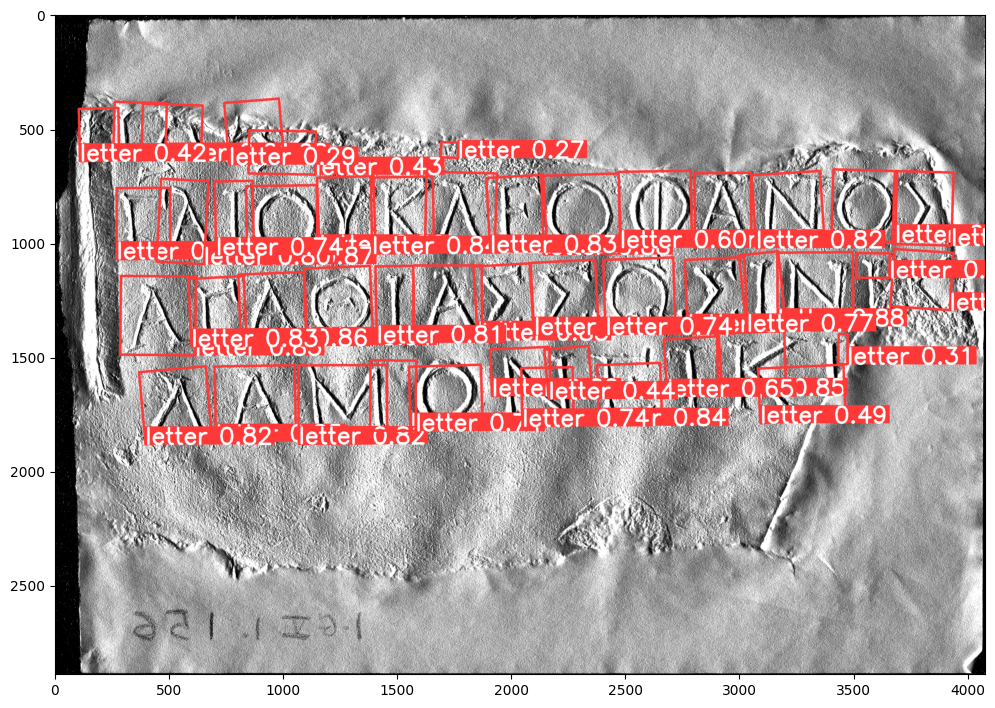

In [8]:
# Load image
image = Image.open(TEST_IMAGE_PATH).convert("RGB")
img_cv2 = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)

# Run Inference
print("Running SAHI Sliced Inference...")
result = get_sliced_prediction(
    TEST_IMAGE_PATH,
    detection_model,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
    postprocess_type="NMS", # Merge overlapping boxes
    postprocess_match_metric="IOS",
)

# Extract Oriented Boxes (SAHI returns standard boxes, we need to dig for OBB if supported)
# Note: SAHI's default output is often axis-aligned. 
# If precise OBB is critical and SAHI flattens them, we might use Ultralytics directly.
# Let's check what we got.
object_prediction_list = result.object_prediction_list
print(f"Found {len(object_prediction_list)} detections.")

# Visualize Basic Detection
result.export_visuals(export_dir="demo_result/")
# Display
plt.figure(figsize=(12, 12))
plt.imshow(Image.open("demo_result/prediction_visual.png"))
plt.show()

In [9]:
# Helper Function: Order Points & Perspective Transform
def crop_and_warp_obb(img, polygon):
    """
    Input: img (cv2), polygon (list of points)
    Output: upright cropped image
    """
    pts = np.array(polygon, dtype="float32")
    
    # Sort points: TL, TR, BR, BL
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    rect[0] = pts[np.argmin(s)]
    rect[2] = pts[np.argmax(s)]
    diff = np.diff(pts, axis=1)
    rect[1] = pts[np.argmin(diff)]
    rect[3] = pts[np.argmax(diff)]
    (tl, tr, br, bl) = rect
    
    # Compute size
    widthA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
    widthB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
    maxWidth = max(int(widthA), int(widthB))
    
    heightA = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
    heightB = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
    maxHeight = max(int(heightA), int(heightB))
    
    # Perspective Transform
    dst = np.array([[0, 0], [maxWidth-1, 0], [maxWidth-1, maxHeight-1], [0, maxHeight-1]], dtype="float32")
    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(img, M, (maxWidth, maxHeight))
    return warped

# --- PROCESS DETECTIONS ---
final_results = [] # Store (x, y, label)

for pred in object_prediction_list:
    # 1. Get Polygon (SAHI preserves mask/polygon if available)
    # If using OBB model, pred.mask or pred.segmentation might hold points
    # For now, let's assume detection is valid.
    
    # NOTE: If SAHI returns a Box, we crop the Box. 
    # If you trained OBB, we ideally want the rotated box.
    # Accessing raw ultralytics result from SAHI can be tricky.
    
    # Fallback: Crop using the Bounding Box (simple crop)
    bbox = pred.bbox.to_xyxy()
    x1, y1, x2, y2 = map(int, bbox)
    
    # Crop (Safe bounds)
    h, w, _ = img_cv2.shape
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    
    crop = img_cv2[y1:y2, x1:x2]
    
    if crop.size == 0: continue

    # 2. Preprocess for Classifier
    # Convert BGR (OpenCV) to RGB (PIL)
    crop_pil = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    input_tensor = cls_transforms(crop_pil).unsqueeze(0).to(DEVICE)
    
    # 3. Classify
    with torch.no_grad():
        outputs = classifier(input_tensor)
        _, preds = torch.max(outputs, 1)
        label_idx = preds.item()
        label_str = CLASS_NAMES[label_idx]
        
    # Store center point and label
    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2
    final_results.append({'x': cx, 'y': cy, 'label': label_str})
    
    # Visualization (Optional)
    # plt.imshow(crop_pil)
    # plt.title(f"Pred: {label_str}")
    # plt.show()

print(f"Classified {len(final_results)} letters.")

Classified 47 letters.


In [10]:
# --- TRANSCRIPT RECONSTRUCTION ---
# 1. Sort by Y coordinate (Top to Bottom)
# Simple sorting doesn't work for lines. We need clustering.
# Letters with similar Y (within 20-50 pixels) should be grouped.

def reconstruct_transcript(results, line_threshold=50):
    # Sort everyone by Y first
    results.sort(key=lambda k: k['y'])
    
    lines = []
    current_line = []
    
    if not results: return ""
    
    # Initialize first line
    current_line.append(results[0])
    current_y_avg = results[0]['y']
    
    for i in range(1, len(results)):
        char = results[i]
        
        # Is this character on the same line? 
        # (Is its Y close to the running average of the current line?)
        if abs(char['y'] - current_y_avg) < line_threshold:
            current_line.append(char)
            # Update average Y of this line
            sum_y = sum(c['y'] for c in current_line)
            current_y_avg = sum_y / len(current_line)
        else:
            # New Line Detected
            # 1. Sort the finished line by X (Left to Right)
            current_line.sort(key=lambda k: k['x'])
            lines.append(current_line)
            
            # Start new line
            current_line = [char]
            current_y_avg = char['y']
            
    # Append last line
    if current_line:
        current_line.sort(key=lambda k: k['x'])
        lines.append(current_line)
        
    # Build String
    full_transcript = []
    for line in lines:
        line_str = "".join([item['label'] for item in line])
        full_transcript.append(line_str)
        
    return "\n".join(full_transcript)

# Run it
transcript = reconstruct_transcript(final_results)
print("-" * 20)
print("FINAL TRANSCRIPT:")
print("-" * 20)
print(transcript)
print("-" * 20)

--------------------
FINAL TRANSCRIPT:
--------------------
EGAA
HE
GATOYKLEOOANOS
T
QTASSWSTNK
AGA
I
NTTK
DAMGONEH
--------------------


In [11]:
import math
import numpy as np

def get_rotated_point(x, y, angle_rad):
    """
    Rotates a point (x, y) by an angle around the origin (0,0).
    Used to 'level' the text lines before sorting.
    """
    cos_val = math.cos(angle_rad)
    sin_val = math.sin(angle_rad)
    # Counter-clockwise rotation to fix the tilt
    x_new = x * cos_val + y * sin_val
    y_new = -x * sin_val + y * cos_val
    return x_new, y_new

def advanced_reconstruct_transcript(results, line_threshold=30):
    """
    1. Calculates the dominant angle of the text from detections.
    2. Rotates all coordinates to make the text 'horizontal'.
    3. Clusters into lines based on the new Y-coordinates.
    4. Sorts lines by X-coordinates.
    """
    if not results:
        return ""

    # --- 1. Determine Global Rotation Angle ---
    # We assume the average angle of all detected boxes is the 'Stone Angle'
    # Note: YOLO OBB angles are usually in radians. 
    # If using SAHI with standard boxes, angle might be 0. 
    # If you used Ultralytics OBB prediction, 'angle' is in the result.
    
    angles = [r.get('angle', 0.0) for r in results]
    
    # If most boxes have 0 angle (standard bbox), skip rotation
    if all(a == 0 for a in angles):
        avg_angle = 0
    else:
        # Calculate median angle to ignore outliers
        avg_angle = np.median(angles)

    print(f"Detected Text Angle: {math.degrees(avg_angle):.2f} degrees")

    # --- 2. Rotate Coordinates for Sorting ---
    # We create 'virtual' coordinates just for sorting. 
    # We rotate the stone NEGATIVE to the angle to make text horizontal.
    
    virtual_points = []
    for item in results:
        vx, vy = get_rotated_point(item['x'], item['y'], -avg_angle)
        item['vx'] = vx
        item['vy'] = vy
        virtual_points.append(item)

    # --- 3. Sort by Virtual Y (Top to Bottom) ---
    virtual_points.sort(key=lambda k: k['vy'])
    
    lines = []
    current_line = []
    
    if not virtual_points: return ""
    
    # Init first line
    current_line.append(virtual_points[0])
    current_vy_avg = virtual_points[0]['vy']
    
    for i in range(1, len(virtual_points)):
        char = virtual_points[i]
        
        # Check proximity in the Rotated Y axis
        if abs(char['vy'] - current_vy_avg) < line_threshold:
            current_line.append(char)
            # Update running average
            sum_vy = sum(c['vy'] for c in current_line)
            current_vy_avg = sum_vy / len(current_line)
        else:
            # Line finished -> Sort it by Virtual X (Left to Right)
            current_line.sort(key=lambda k: k['vx'])
            lines.append(current_line)
            
            # Start new line
            current_line = [char]
            current_vy_avg = char['vy']
            
    # Append last line
    if current_line:
        current_line.sort(key=lambda k: k['vx'])
        lines.append(current_line)

    # --- 4. Build String ---
    full_transcript = []
    for line in lines:
        line_str = "".join([item['label'] for item in line])
        full_transcript.append(line_str)
        
    return "\n".join(full_transcript)

In [13]:
# Run it
transcript = advanced_reconstruct_transcript(final_results)
print("-" * 20)
print("FINAL TRANSCRIPT:")
print("-" * 20)
print(transcript)
print("-" * 20)

Detected Text Angle: 0.00 degrees
--------------------
FINAL TRANSCRIPT:
--------------------
EGAA
HE
TYKLEOOANOS
GAO
T
K
SWSTN
GAQTAS
A
I
NTTK
GONEH
DAM
--------------------
